# Task 5 — Capstone redesign

This redesign removes the clutter, keeps one clear message, and uses a single strong highlight. The key is that the eye sees one target quickly and the rest of the chart behaves as structured context.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

base = Path('data')
gap = pd.read_csv(base / 'gapminder.csv')
print(gap.head())

       country  year         pop continent  lifeExp   gdpPercap
0  Afghanistan  1952   8425333.0      Asia   28.801  779.445314
1  Afghanistan  1957   9240934.0      Asia   30.332  820.853030
2  Afghanistan  1962  10267083.0      Asia   31.997  853.100710
3  Afghanistan  1967  11537966.0      Asia   34.020  836.197138
4  Afghanistan  1972  13079460.0      Asia   36.088  739.981106


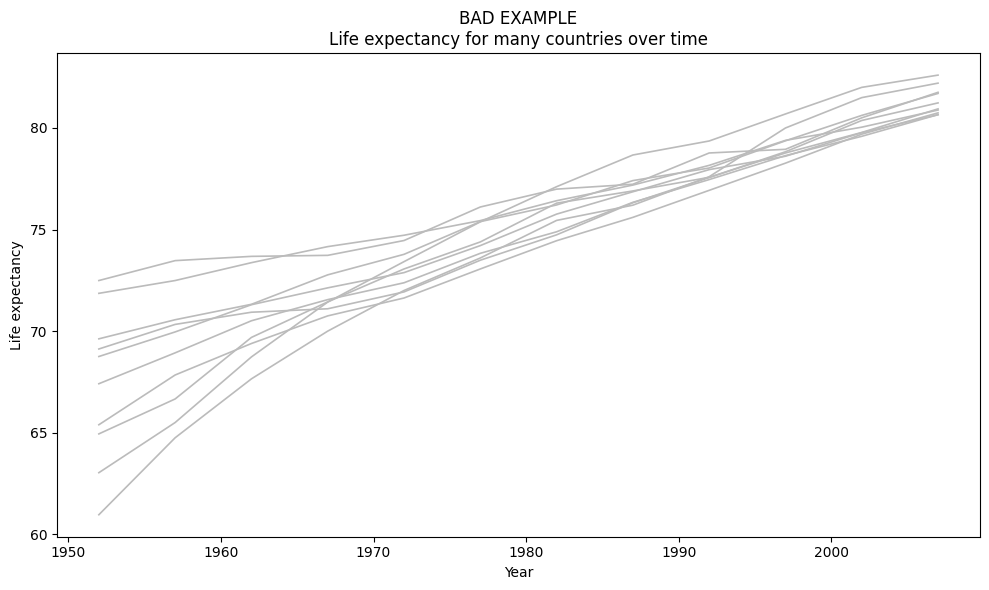

In [2]:
# Bad example
fig, ax = plt.subplots(figsize=(10, 6))
for country in gap[gap['year'] == 2007].sort_values('lifeExp', ascending=False).head(10)['country']:
    series = gap[(gap['country'] == country)].sort_values('year')
    ax.plot(series['year'], series['lifeExp'], color='#bbbbbb', linewidth=1.2)
ax.set_title('BAD EXAMPLE\nLife expectancy for many countries over time', loc='center')
ax.set_xlabel('Year')
ax.set_ylabel('Life expectancy')
fig.tight_layout()

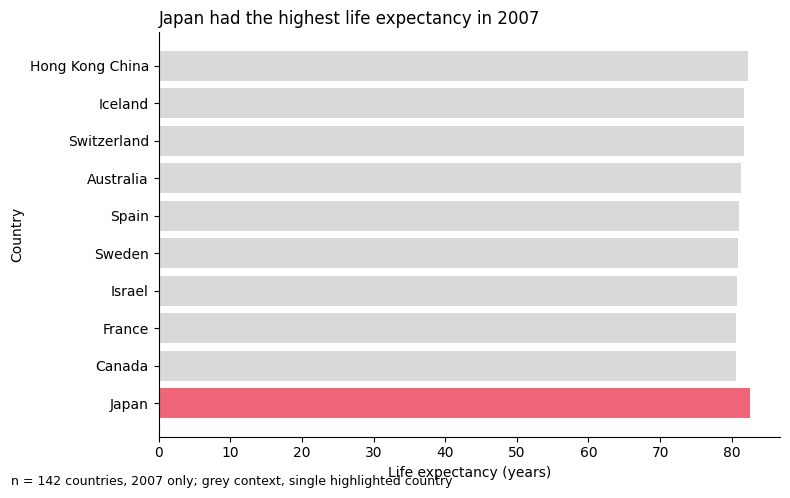

In [3]:
# Redesigned chart
subset = gap[gap['year'] == 2007].sort_values('lifeExp', ascending=False).head(10)
highlight = subset.iloc[0]
context = subset[subset['country'] != highlight['country']]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(context['country'], context['lifeExp'], color='#d9d9d9', height=0.8)
ax.barh([highlight['country']], [highlight['lifeExp']], color='#ee6677', height=0.8)
ax.set_title('Japan had the highest life expectancy in 2007', loc='left')
ax.set_xlabel('Life expectancy (years)')
ax.set_ylabel('Country')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
ax.invert_yaxis()
fig.text(0.02, 0.02, 'n = 142 countries, 2007 only; grey context, single highlighted country', fontsize=9)
fig.tight_layout()

In [4]:
# Interpretation
# The redesign uses a single bit of strong colour and grey context, so the target is the only item that pops out. It relies on proximity and the bar ordering to show relative rankings; the message is not hidden in a large legend or a cluttered time series.
# A reader could infer: 'Japan had the highest life expectancy in 2007.' The trade-off is that the detailed time history of every country is no longer visible, but that is the deliberate cost of focusing on one message.